# TC5061 – Notebook Baseline: Bank Marketing
**Alumno:** Diego Cameros
**Materia:** Operaciones de Aprendizaje Automático (MLOps)

## Objetivo
El objetivo de este trabajo es poder predecir cuáles serán los clientes potenciales que comprarán el producto que el banco. 

In [ ]:
import sys

import mlflow
import sklearn
import pandas as pd

print("Python en uso:", sys.executable)
print("MLflow:", mlflow.__version__)
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)

Python en uso: c:\Users\diego\anaconda3\envs\mlops\python.exe
MLflow: 3.16.1
scikit-learn: 1.9.1
pandas: 3.0.6


## Paso 1: Carga y descripción del dataset
### 1.1 Extracción de los datos

In [ ]:
import zipfile
from pathlib import Path

ZIP_PATH = Path("bank+marketing.zip")

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(DATA_DIR)

for interno in ["bank.zip", "bank-additional.zip"]:
    with zipfile.ZipFile(DATA_DIR / interno) as z:
        z.extractall(DATA_DIR)

for archivo in sorted(DATA_DIR.rglob("*.csv")):
    if "__MACOSX" not in str(archivo):
        print(archivo)

data\bank-additional\bank-additional-full.csv
data\bank-additional\bank-additional.csv
data\bank-full.csv
data\bank.csv


### 1.2 Selección y carga del dataset

Para el presente trabajo se eligió el dataset más completo que fue el de bank-additional-full.csv ya que este dataset concentraba más información que los otros y justo esto es lo que buscábamos para hacer el análisis y poder hacer predicciones de quiénes podrían comprar el producto que el banco intentaba vender. 

In [ ]:
CSV_PATH = DATA_DIR / "bank-additional" / "bank-additional-full.csv"

with open(CSV_PATH, encoding="utf-8") as f:
    for _ in range(3):
        print(f.readline())

"age";"job";"marital";"education";"default";"housing";"loan";"contact";"month";"day_of_week";"duration";"campaign";"pdays";"previous";"poutcome";"emp.var.rate";"cons.price.idx";"cons.conf.idx";"euribor3m";"nr.employed";"y"

56;"housemaid";"married";"basic.4y";"no";"no";"no";"telephone";"may";"mon";261;1;999;0;"nonexistent";1.1;93.994;-36.4;4.857;5191;"no"

57;"services";"married";"high.school";"unknown";"no";"no";"telephone";"may";"mon";149;1;999;0;"nonexistent";1.1;93.994;-36.4;4.857;5191;"no"



In [ ]:
df = pd.read_csv(CSV_PATH, sep=";")

print("Dimensiones (filas, columnas):", df.shape)

df.info()

df.head()

Dimensiones (filas, columnas): (41188, 21)
<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17 

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
conteo_unknown = (df == "unknown").sum()

conteo_unknown = conteo_unknown[conteo_unknown > 0].sort_values(ascending=False)

tabla_unknown = pd.DataFrame({
    "conteo": conteo_unknown,
    "porcentaje": (conteo_unknown / len(df) * 100).round(2)
})
print(tabla_unknown)

filas_con_unknown = (df == "unknown").any(axis=1).sum()
print(f"\nFilas con al menos un 'unknown': {filas_con_unknown} "
      f"({filas_con_unknown / len(df) * 100:.2f}%)")

           conteo  porcentaje
default      8597       20.87
education    1731        4.20
housing       990        2.40
loan          990        2.40
job           330        0.80
marital        80        0.19

Filas con al menos un 'unknown': 10700 (25.98%)


In [ ]:
num_cols = df.select_dtypes(include="number").columns.tolist()

cat_cols = [c for c in df.columns if c not in num_cols]

print(f"Numéricas ({len(num_cols)}): {num_cols}")
print(f"Categóricas ({len(cat_cols)}): {cat_cols}\n")

for col in cat_cols:
    print(f"{col} ({df[col].nunique()} categorías): {sorted(df[col].unique())}")

Numéricas (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categóricas (11): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']

job (12 categorías): ['admin.', 'blue-collar', 'entrepreneur', 'housemaid', 'management', 'retired', 'self-employed', 'services', 'student', 'technician', 'unemployed', 'unknown']
marital (4 categorías): ['divorced', 'married', 'single', 'unknown']
education (8 categorías): ['basic.4y', 'basic.6y', 'basic.9y', 'high.school', 'illiterate', 'professional.course', 'university.degree', 'unknown']
default (3 categorías): ['no', 'unknown', 'yes']
housing (3 categorías): ['no', 'unknown', 'yes']
loan (3 categorías): ['no', 'unknown', 'yes']
contact (2 categorías): ['cellular', 'telephone']
month (10 categorías): ['apr', 'aug', 'dec', 'jul', 'jun', 'mar', 'may', 'nov', 'oct', 'sep']
day_of_week (5 categorías): ['fri',

| Variable | Tipo | Significado |
|---|---|---|
| age | Numérica | Edad del cliente, en años. |
| job | Categórica | Ocupación del cliente |
| marital | Categórica | Es el estado civil del cliente |
| education | Categórica | Es el rango académico del cliente |
| default | Categórica | indica si el cliente tiene un crédito en incumplimiento |
| housing | Categórica | Indica si el cliente tiene un crédito de vivienda |
| loan | Categórica | nos muestra si el cliente tiene un préstamo personal |
| contact | Categórica | Es el tipo de teléfono usado en el último contacto de la campaña (celular o fijo). |
| month | Categórica | el mes el último contacto |
| day_of_week | Categórica | es el día del último contacto  |
| poutcome | Categórica | es el resultado de la campaña de marketing anterior |
| duration | numérica | es la duración del último contacto, en segundos. |
| campaign | numérica | es el número de contactos durante esta campaña. |
| pdays | numérica | indica los días desde que se contactó al cliente en una campaña anterior. |
| previous | numérica | indica los número de contactos antes de esta campaña. |
| emp.var.rate | numérica | indica la tasa de variación del empleo (trimestral). |
| cons.price.idx | numérica | es el Índice de precios al consumidor |
| cons.conf.idx | numérica | es el Índice de confianza del consumidor |
| euribor3m | numérica | este es un índice me parece de interes europeo |
| nr.employed | numérica | es el número de empleados (trimestral), indicador del mercado laboral. |
| y | categórica | es la Variable objetivo: si el cliente contrató el depósito a plazo. |

La estructura del dataset está lleno con estas variables numéricas (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'] y estás Categóricas (11): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y'] de las cuales la variable "y" es la variable objetivo. 

## Paso 2: Análisis exploratorio de datos (EDA)
### 2.1 Distribución de la variable objetivo

     conteo  porcentaje
y                      
no    36548       88.73
yes    4640       11.27


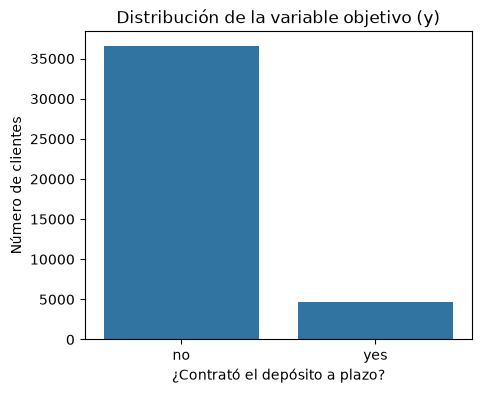

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

tabla_y = pd.DataFrame({
    "conteo": df["y"].value_counts(),
    "porcentaje": (df["y"].value_counts(normalize=True) * 100).round(2)
})
print(tabla_y)

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="y", ax=ax)
ax.set_title("Distribución de la variable objetivo (y)")
ax.set_xlabel("¿Contrató el depósito a plazo?")
ax.set_ylabel("Número de clientes")
plt.show()

En la gráfica podemos ver que existe un resultado muy interesante puesto que se ve un 88.7 con "no" y el 11.3 con "yes" por cada cliente que contrata ocho dicen que no entonces podemos ver que existe un desbalance de clases. 

### 2.2 Estadísticas descriptivas de las variables numéricas

In [ ]:
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


In [ ]:
print(f"Clientes con pdays = 999: {(df['pdays'] == 999).mean() * 100:.2f}%\n")

pd.crosstab(df["pdays"] == 999, df["poutcome"])

Clientes con pdays = 999: 96.32%



poutcome,failure,nonexistent,success
pdays,,,
False,142,0,1373
True,4110,35563,0


In [ ]:
inconsistentes = (df["pdays"] == 999) & (df["poutcome"] == "failure")

df.loc[inconsistentes, "previous"].value_counts().sort_index()

previous
1    3696
2     349
3      50
4      12
5       2
6       1
Name: count, dtype: int64

Al analizar los datos puedo ver que hay datos faltantes disfrazados como "unknown" (26% de las filas tiene al menos uno; casi todos vienen de default).
housing y loan tienen exactamente 990 "unknown". Como un primer acercamiento puedo pensar que existe una relación entre estos datos.

month tiene solo 10 categorías: no hay registros de enero ni febrero. Y day_of_week solo trae días hábiles.

poutcome tiene una categoría nonexistent. Al inicio creí que esto era una rasgo faltante de información pero al analizar más a fondo veo que no es así sino que posiblemente significa que al cliente nunca se le contactó en una campaña anterior.

Desbalance: 88.7% "no" vs 11.3% "yes". La exactitud (accuracy) por sí sola es engañosa.

pdays = 999 significa "nunca contactado"; coincide con poutcome = nonexistent, pero hay 4,110 clientes con poutcome = failure y pdays = 999: inconsistencia.
pdays = 999 mezcla dos situaciones: "nunca contactado" y "contactado, pero sin registro de días" (4,110 casos con previous ≥ 1). Es una variable poco confiable; decidir su tratamiento en el Paso 3.

### 2.3 Relación de variables categóricas con la variable objetivo

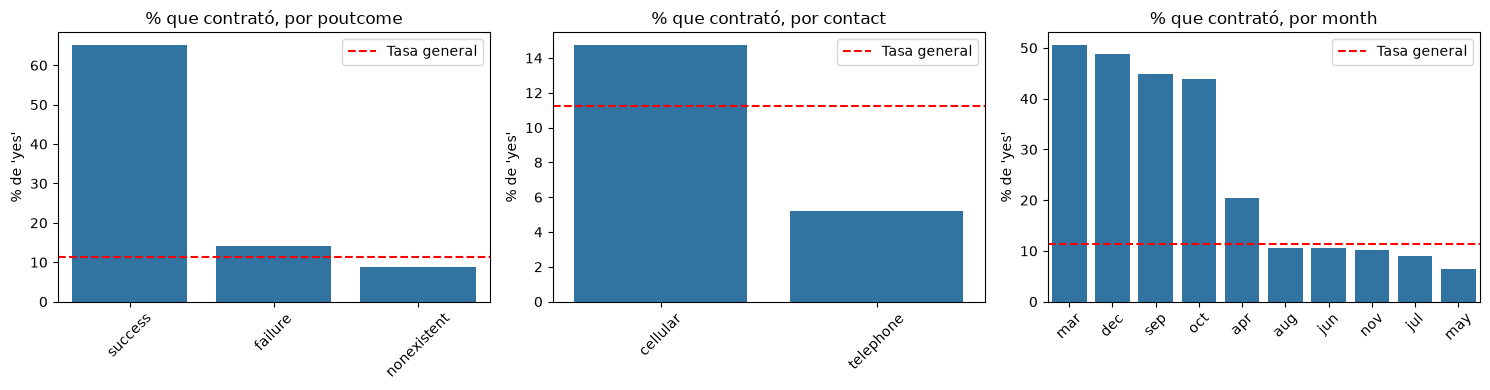

In [ ]:
tasa_general = (df["y"] == "yes").mean() * 100

cols_relacion = ["poutcome", "contact", "month"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, cols_relacion):
    tasa = (df.groupby(col)["y"]
              .apply(lambda s: (s == "yes").mean() * 100)
              .sort_values(ascending=False))

    sns.barplot(x=tasa.index, y=tasa.values, ax=ax)

    ax.axhline(tasa_general, linestyle="--", color="red", label="Tasa general")
    ax.set_title(f"% que contrató, por {col}")
    ax.set_ylabel("% de 'yes'")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
resumen_mes = df.groupby("month").agg(
    llamadas=("y", "size"),
    tasa_yes=("y", lambda s: round((s == "yes").mean() * 100, 2))
).sort_values("tasa_yes", ascending=False)

resumen_mes["pct_del_total"] = (resumen_mes["llamadas"] / len(df) * 100).round(2)

resumen_mes

,llamadas,tasa_yes,pct_del_total
month,,,
mar,546,50.55,1.33
dec,182,48.90,0.44
sep,570,44.91,1.38
oct,718,43.87,1.74
apr,2632,20.48,6.39
aug,6178,10.60,15.00
jun,5318,10.51,12.91
nov,4101,10.14,9.96
jul,7174,9.05,17.42


La tasa de éxito por mes tiene relación inversa con el volumen de llamadas: los meses con tasas altas tienen muy pocos registros. Esto me hace pensar que los meses que tienen pocas llamadas el banco selecciona con más cuidado a los clientes potenciales eligiendo a los que tienen mayor probabilidad de comprar el producto que en los meses que tienen mucha actividad donde parece que hablan a ciegas. 

### 2.4 Relación de variables numéricas con la variable objetivo


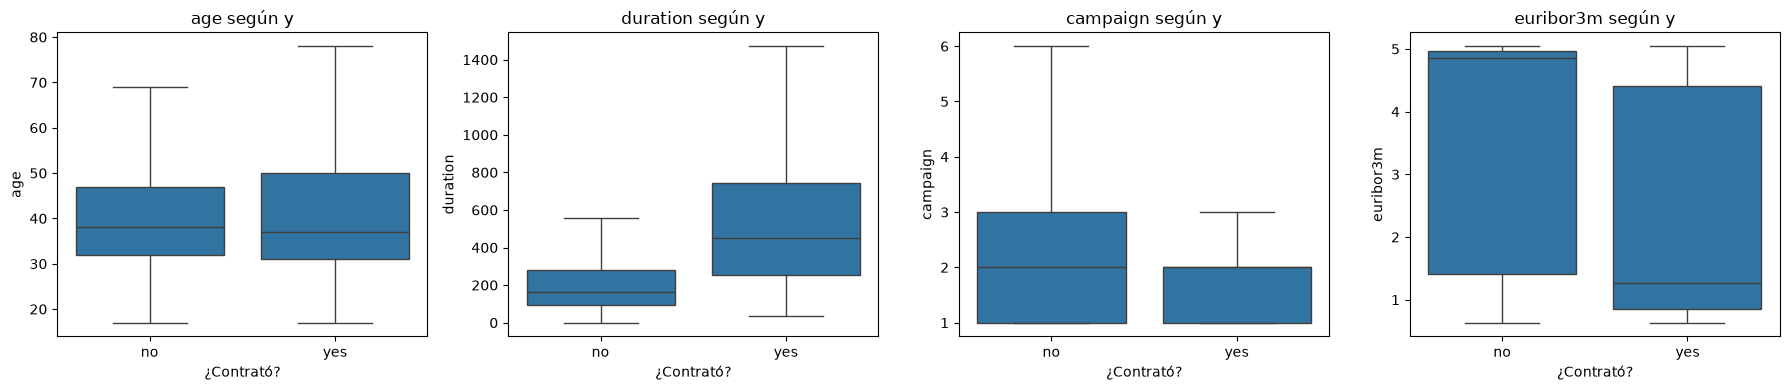

In [ ]:
cols_num_relacion = ["age", "duration", "campaign", "euribor3m"]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, col in zip(axes, cols_num_relacion):
   
    sns.boxplot(data=df, x="y", y=col, ax=ax, showfliers=False)
    ax.set_title(f"{col} según y")
    ax.set_xlabel("¿Contrató?")

plt.tight_layout()
plt.show()

La variable númerica de duración se excluirá porque incluirla da un modelo que aparentemente se ve muy fuerte pero en la práctica resulta inútil ya que la duración no la podemos predecir. 

## Paso 3: Limpieza de datos
### 3.1 Duplicados

In [ ]:
n_dup = df.duplicated().sum()
print(f"Filas duplicadas: {n_dup}")

df_clean = df.drop_duplicates().copy()
print(f"Registros antes: {len(df)} | después: {len(df_clean)}")

Filas duplicadas: 12
Registros antes: 41188 | después: 41176


### 3.2 Eliminación de columnas y conversión de tipos

Se encontraron 12 filas idénticas. Un registro repetido pesa doble en el entrenamiento, así que se eliminaron para que cada cliente cuente una sola vez.

Que un dato sea desconocido no quiere decir que debamos descartarlo: esas filas tienen información importante en sus otras columnas. Eliminar todas las filas con algún "unknown" habría significado perder el 26% del dataset.

El valor 999 debería significar "nunca contactado", pero 4,110 clientes con 999 sí habían sido contactados antes (su `previous` era 1 o más). Es una columna inconsistente que confundiría al modelo, y su información ya está cubierta por `previous` y `poutcome`.

Era la variable que mejor separaba a los grupos, pero representa una fuga de información: la duración solo se conoce cuando la llamada ya terminó, y el banco quiere usar el modelo antes de llamar. Incluirla daría métricas excelentes pero un modelo inútil en la práctica.

Un cliente con 56 llamadas es un caso raro, pero posible; no parece un error de captura. Como este es un modelo base, se mantuvo un procesamiento simple y este ajuste queda como posible mejora futura.

Los modelos de scikit-learn necesitan la etiqueta en formato numérico, así que "yes" pasó a 1 y "no" a 0.

In [ ]:
df_clean = df_clean.drop(columns=["duration", "pdays"])

df_clean["y"] = (df_clean["y"] == "yes").astype(int)

print("Dimensiones finales:", df_clean.shape)
print("Valores de y:", df_clean["y"].value_counts().to_dict())
print("Columnas:", df_clean.columns.tolist())

Dimensiones finales: (41176, 19)
Valores de y: {0: 36537, 1: 4639}
Columnas: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


## Paso 4: Entrenamiento del modelo base

In [ ]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.2
RANDOM_STATE = 42

X = df_clean.drop(columns="y")
y = df_clean["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

print(f"Entrenamiento: {X_train.shape} | % de 'sí': {y_train.mean()*100:.2f}%")
print(f"Prueba:        {X_test.shape} | % de 'sí': {y_test.mean()*100:.2f}%")

Entrenamiento: (32940, 18) | % de 'sí': 11.27%
Prueba:        (8236, 18) | % de 'sí': 11.27%


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

num_features = X.select_dtypes(include="number").columns.tolist()
cat_features = [c for c in X.columns if c not in num_features]

preprocesador = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])

PARAMS = {"C": 1.0, "max_iter": 1000, "solver": "lbfgs"}

modelo = Pipeline([
    ("prep", preprocesador),
    ("clf", LogisticRegression(**PARAMS, random_state=RANDOM_STATE)),
])

modelo.fit(X_train, y_train)
print("Modelo entrenado.")
print(f"Numéricas ({len(num_features)}): {num_features}")
print(f"Categóricas ({len(cat_features)}): {cat_features}")

Modelo entrenado.
Numéricas (8): ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categóricas (10): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


## Paso 5: Evaluación del modelo

  accuracy: 0.8980
 precision: 0.6507
    recall: 0.2047
        f1: 0.3115
   roc_auc: 0.8003

               precision    recall  f1-score   support

          no       0.91      0.99      0.94      7308
          sí       0.65      0.20      0.31       928

    accuracy                           0.90      8236
   macro avg       0.78      0.60      0.63      8236
weighted avg       0.88      0.90      0.87      8236



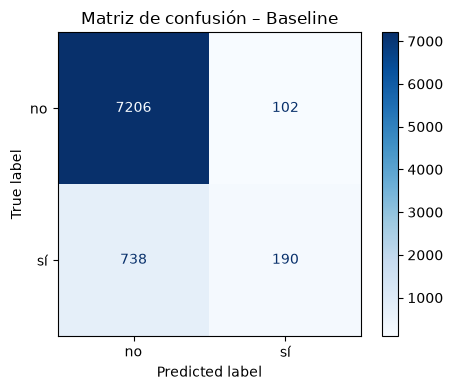

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay)

y_proba = modelo.predict_proba(X_test)[:, 1]

METRICAS = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred),
    "recall": recall_score(y_test, y_pred),
    "f1": f1_score(y_test, y_pred),
    "roc_auc": roc_auc_score(y_test, y_proba),
}
for nombre, valor in METRICAS.items():
    print(f"{nombre:>10}: {valor:.4f}")

print("\n", classification_report(y_test, y_pred, target_names=["no", "sí"]))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["no", "sí"], cmap="Blues", ax=ax
)
ax.set_title("Matriz de confusión – Baseline")
plt.tight_layout()
plt.savefig("matriz_confusion_baseline.png", dpi=120)
plt.show()

Los resultados obtenidos son muy interesantes

La exactitud de los resultados lo obtuvimos del 89.8% contra los 88.7% del modelo que siempre dice "no". Pero esta por sí sola no nos dice mucho. 
En el recall nos arrojó un resultado del 20% para los 928 clientes que sí contrataron, para estos el modelo encontró solo 190, se le escaparon 738 oportunidades. 
La precisión la obtuvimos del 65% esto nos indica que de las 292 llamadas que el modelo recomendaría 190 terminarían en "sí". Lo cual si el banco llamara al azar solo acertaría el 11% entonces el modelo nos indica que es casi 6 veces mejor que llamar a ciegas. 
Para ROC-AUC se obtuvo un resultado del 0.80 el modelo ordena bien a los clientes por la probabilidad, entonces el recall solo dice "sí" cuando la probabilidad pasa del 50% y con tan pocos "sí" en los datos no se atreve. Esa es la oportunidad de mejora más clara. 

## Paso 6: Registro del experimento en MLflow

In [ ]:
import mlflow
import mlflow.sklearn

mlflow.set_tracking_uri("sqlite:///mlflow.db")

mlflow.set_experiment("bank-marketing-baseline")

with mlflow.start_run(run_name="logreg_baseline") as run:

    mlflow.log_params(PARAMS)

    mlflow.log_params({
        "modelo": "LogisticRegression",
        "dataset": "bank-additional-full.csv",
        "test_size": TEST_SIZE,
        "random_state": RANDOM_STATE,
        "n_train": len(X_train),
        "n_test": len(X_test),
        "columnas_eliminadas": "duration, pdays",
    })

    mlflow.log_metrics(METRICAS)

    mlflow.log_artifact("matriz_confusion_baseline.png")

    mlflow.sklearn.log_model(
        sk_model=modelo,
        name="modelo_baseline",
        input_example=X_train.head(5),
    )

    print("Run registrado. ID:", run.info.run_id)

c:\Users\diego\anaconda3\envs\mlops\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
c:\Users\diego\anaconda3\envs\mlops\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains mis

Run registrado. ID: 213d3fae9b214798ae1cda95ad52d3cb


### Evidencia del experimento en MLflow

**Run `logreg_baseline`: métricas y parámetros**

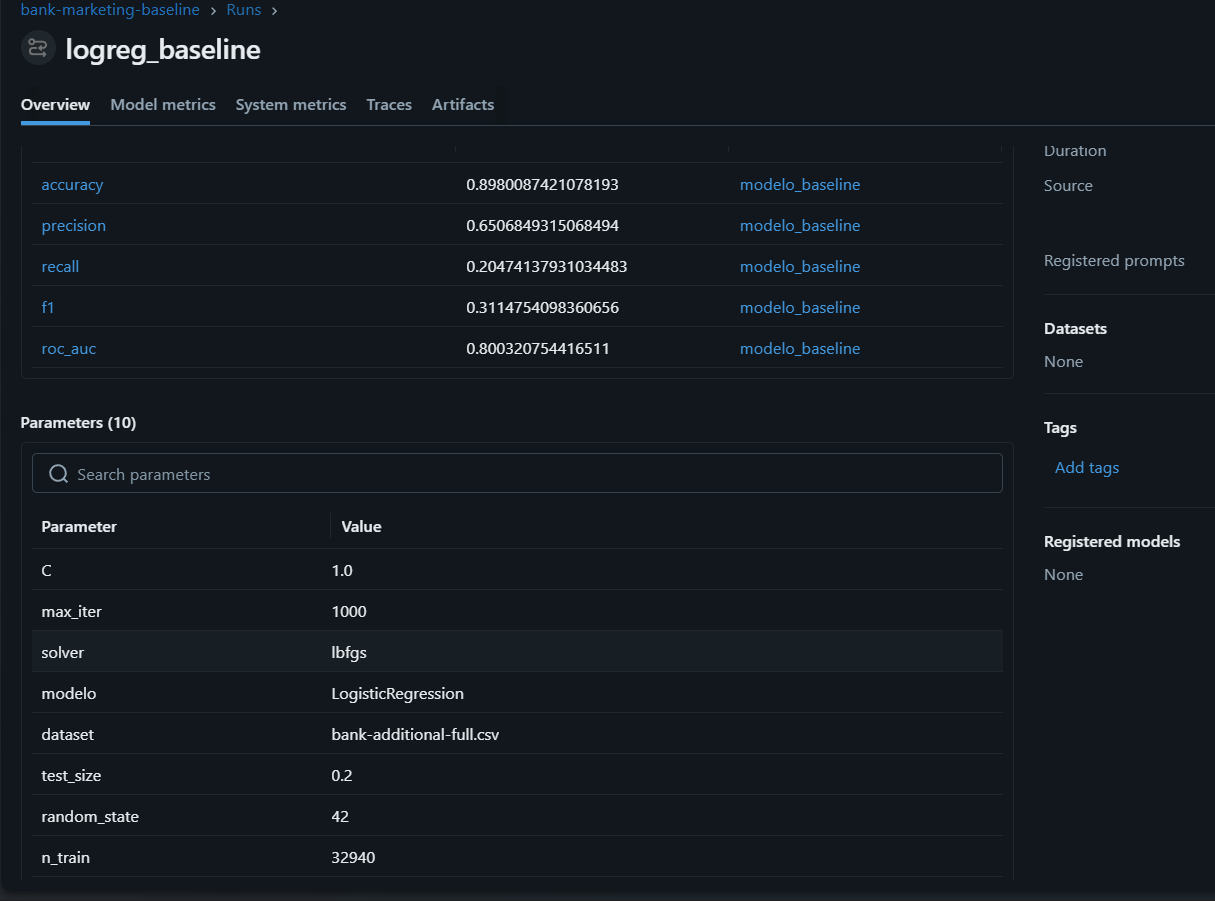

**Artefacto: matriz de confusión**

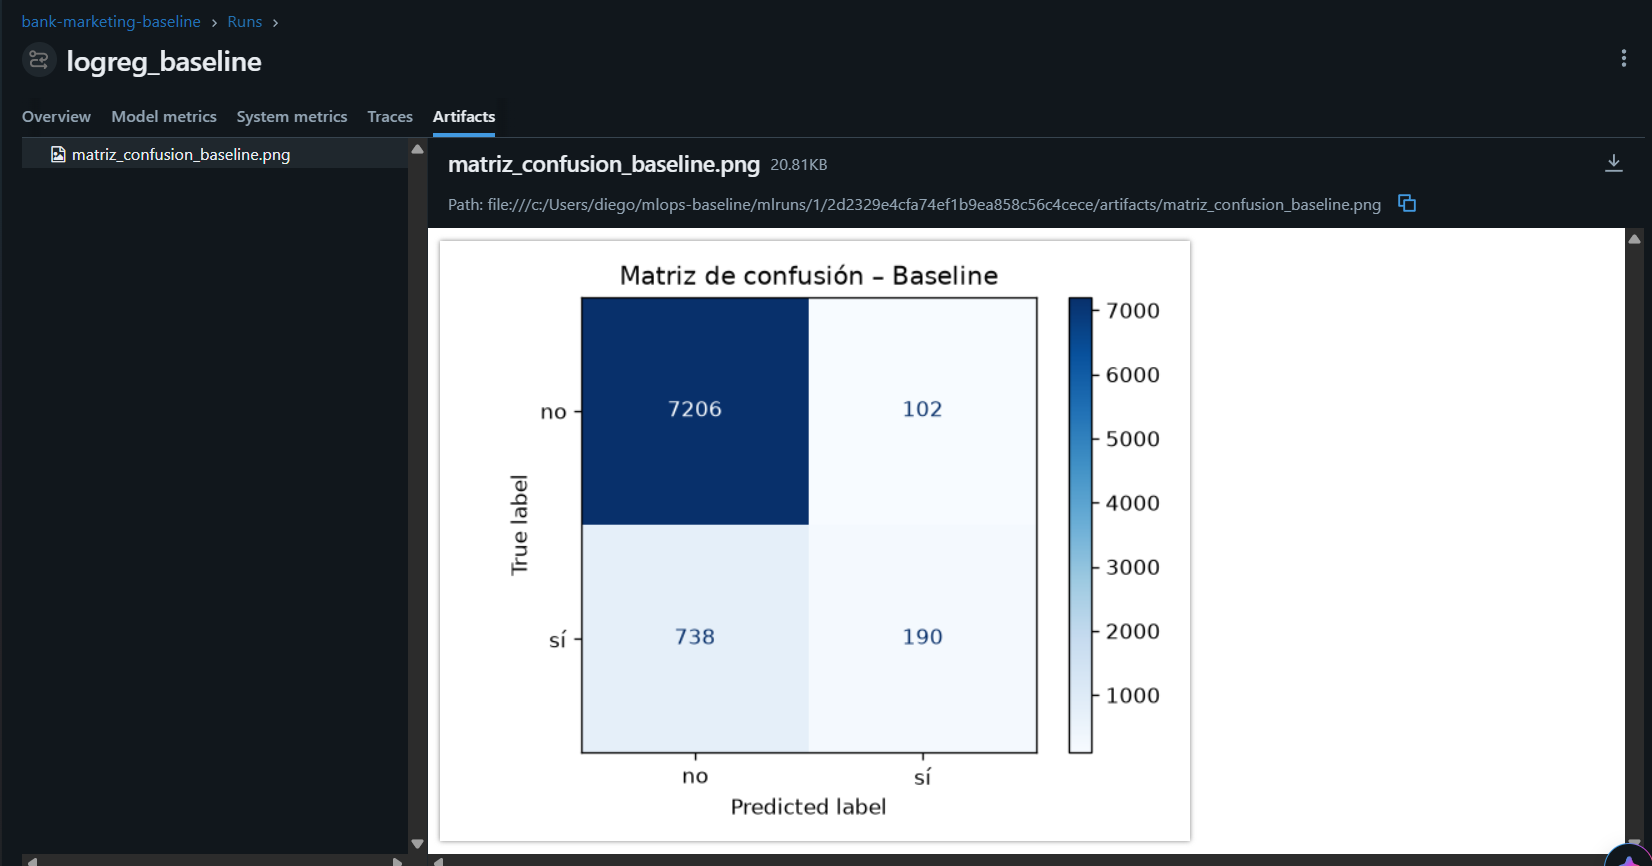

**Modelo guardado y sus archivos**

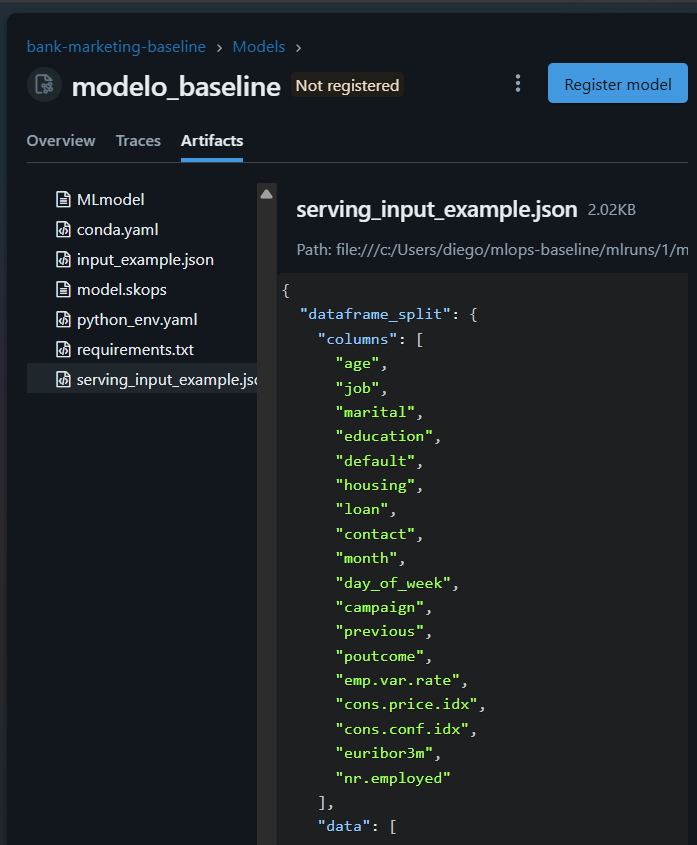

**Dos corridas registradas (reproducibilidad)**

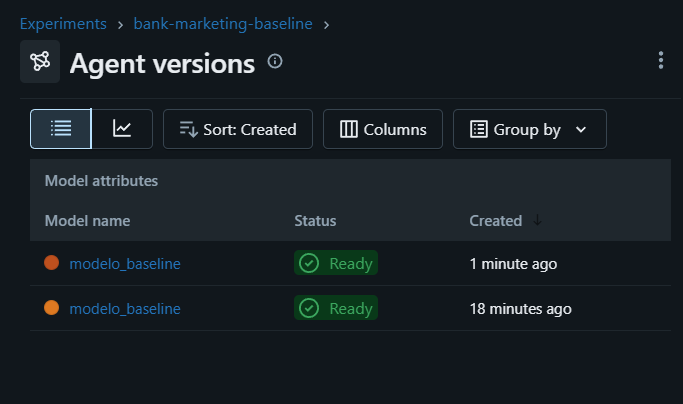

## Paso 7: Reflexión

Al analizar el dataset Bank Marketing del repositorio de UCI, noté que los datos venían bien organizados y estructurados, algo poco común en la vida real. Sin embargo, esa organización era engañosa: durante la exploración encontré variables que en los números parecían muy prometedoras, pero que en la práctica eran una trampa. El caso más claro fue duration, la duración de la llamada. Era la variable que mejor separaba a quienes contrataban de quienes no, pero el banco no puede saber cuánto durará una llamada antes de hacerla; cuando ese dato existe, la respuesta del cliente ya se conoce. Usarla habría producido un modelo excelente en papel e inútil en la práctica. También descubrí faltantes disfrazados como "unknown" y un código 999 en pdays que mezclaba situaciones distintas. Otro hallazgo importante fue que un modelo que siempre responde "no" alcanzaría una exactitud de 88.7%, una cifra que luce estupenda pero no identifica a ningún cliente interesado.

Para mejorar este flujo con prácticas de MLOps, registraría varias corridas en MLflow para comparar configuraciones y elegir con evidencia el mejor resultado.

Al ejecutar el notebook dos veces, MLflow registró dos corridas con métricas idénticas hasta el último decimal. Esto se debe a que fijé una semilla aleatoria: la división entre entrenamiento y prueba es un sorteo, y la semilla hace que salga igual cada vez. Sin ella, si una métrica mejorara después de un cambio, no podría saber si fue por el cambio o por un sorteo más favorable.

En mi trabajo estamos empezando a crear un catálogo de todas nuestras automatizaciones, con registro de qué se modificó y por qué. Esto se conecta directamente con MLOps: el catálogo funciona como un registro de modelos y el historial de cambios como el seguimiento de experimentos.